## Homework 5, part 2d

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

w = 0.8
beta = 1.0
g = 2.0
tau_a = 120.0
eta = 1000.0

def sigmoid(x):
    z = np.clip(eta * x, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def rhs(t, y, I_L, I_R, w):
    uL, uR, aL, aR = y

    d_uL = -uL + sigmoid(w*uL - beta*uR - g*aL + I_L)
    d_uR = -uR + sigmoid(w*uR - beta*uL - g*aR + I_R)

    d_aL = (-aL + uL) / tau_a
    d_aR = (-aR + uR) / tau_a

    return [d_uL, d_uR, d_aL, d_aR]

def run_model(I_L=1.3, I_R=1.3, w=0.8):
    t_end = 30 * tau_a
    y0 = [1.0, 0.0, 0.0, 0.5]

    sol = solve_ivp(
        rhs, (0, t_end), y0,
        args=(I_L, I_R, w),
        method="Radau",
        rtol=1e-8, atol=1e-10,
        max_step=0.5,
        dense_output=False
    )

    return sol.t, sol.y

def find_handovers(t, uL, uR):
    # Winner is whichever population has larger activity.
    winner = np.where(uL > uR, 1, -1)

    # Find indices at which the winning population changes.
    idx = np.where(winner[1:] != winner[:-1])[0] + 1

    # Interpolate the crossing uL = uR for a better estimate.
    crossings = []
    for k in idx:
        d0 = uL[k-1] - uR[k-1]
        d1 = uL[k] - uR[k]

        if d1 != d0:
            tc = t[k-1] - d0 * (t[k] - t[k-1]) / (d1 - d0)
        else:
            tc = t[k]

        crossings.append((tc, winner[k]))

    return crossings

def dominance_durations(t, uL, uR):
    crossings = find_handovers(t, uL, uR)
    durations_L, durations_R = [], []

    # Each pair of successive handovers defines a dominance interval.
    for j in range(1, len(crossings)):
        t0, winner = crossings[j-1]
        t1, _ = crossings[j]

        # Discard the first three handovers to remove transients.
        if j-1 < 3:
            continue

        if winner == 1:
            durations_L.append(t1 - t0)
        else:
            durations_R.append(t1 - t0)

    return np.array(durations_L), np.array(durations_R), crossings


In [8]:
# (i) Plot the symmetric case
t, y = run_model(I_L=1.3, I_R=1.3, w=0.8)
uL, uR, aL, aR = y

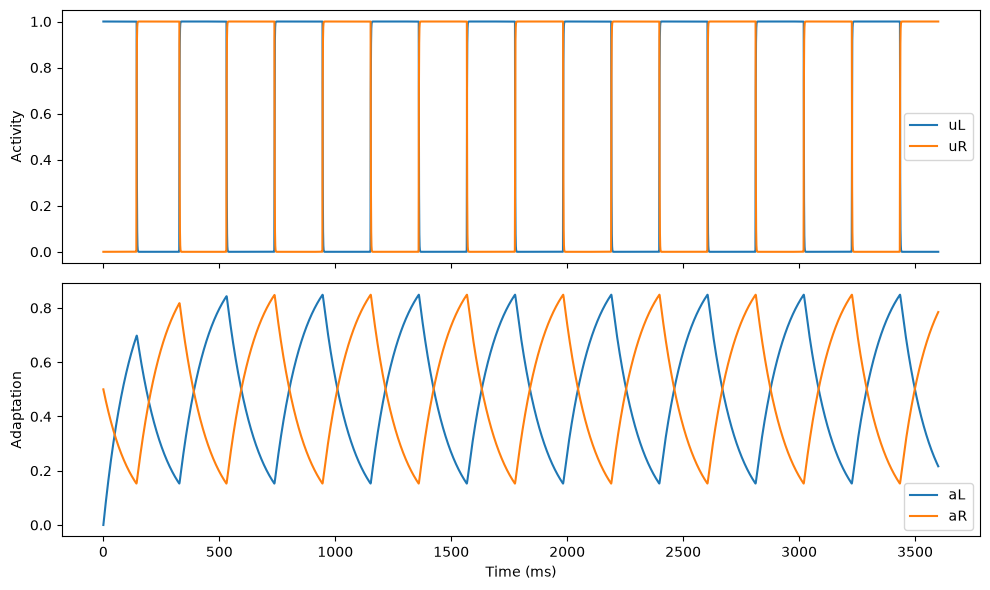

In [9]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
ax[0].plot(t, uL, label="uL")
ax[0].plot(t, uR, label="uR")
ax[0].set_ylabel("Activity")
ax[0].legend()

ax[1].plot(t, aL, label="aL")
ax[1].plot(t, aR, label="aR")
ax[1].set_xlabel("Time (ms)")
ax[1].set_ylabel("Adaptation")
ax[1].legend()

plt.tight_layout()
plt.show()

In [4]:
# part 2

In [12]:
# (ii) Compare mean dominance durations with part (c)
t, y = run_model(I_L=1.6, I_R=1.3, w=0.8)
uL, uR = y[0], y[1]

TL, TR, crossings = dominance_durations(t, uL, uR)

In [13]:
print("Simulated mean dominance durations:")
print("TL =", np.mean(TL), "ms")
print("TR =", np.mean(TR), "ms")

BL = (1.6 - beta) / g
BR = (1.3 - beta) / g

TL_theory = tau_a * np.log((1 - BL) / BR)
TR_theory = tau_a * np.log((1 - BR) / BL)

print("Binary approximation:")
print("TL =", TL_theory, "ms")
print("TR =", TR_theory, "ms")

Simulated mean dominance durations:
TL = 186.05514927176023 ms
TR = 126.57732090454475 ms
Binary approximation:
TL = 184.85340491365787 ms
TR = 124.97446497937932 ms


In [22]:
# part 3

In [24]:
# (iii) Repeat below the switching window
w_low = 0.3
t, y = run_model(I_L=1.3, I_R=1.3, w=w_low)
uL, uR = y[0], y[1]

TL_low, TR_low, crossings_low = dominance_durations(t, uL, uR)

In [16]:
Tdom_theory = tau_a * np.log(
    (w_low + 1.3) / (g - w_low - 1.3)
)

print("w = 0.3:")
print("Mean TL =", np.mean(TL_low), "ms")
print("Mean TR =", np.mean(TR_low), "ms")
print("Comparison formula =", Tdom_theory, "ms")

w = 0.3:
Mean TL = 166.2188617465093 ms
Mean TR = 166.1935964844205 ms
Comparison formula = 166.3553233343869 ms
